# India Supermarket & Grocery Sales: generate messy + clean data, all inside Colab
No uploads needed. Run the cells top to bottom (Runtime > Run all).

1. Generate a synthetic *true* dataset (5,000 order lines, Apr-Sep 2026, based on the supermarket deck)
2. Corrupt it into a **messy** dataset
3. Clean it back into a **clean** dataset and check it
4. Download both CSVs

In [1]:
import numpy as np, pandas as pd, random

## 1-2. Generate the true data, then make it messy

In [2]:
rng = np.random.default_rng(42); random.seed(42)
N = 5000
stores={'ST01':('Mumbai','Metro'),'ST02':('Delhi','Metro'),'ST03':('Bangalore','Metro'),'ST04':('Chennai','Metro'),
        'ST05':('Pune','Tier 2'),'ST06':('Jaipur','Tier 2'),'ST07':('Coimbatore','Tier 2'),'ST08':('Lucknow','Tier 2'),
        'ST09':('Trichy','Tier 3'),'ST10':('Madurai','Tier 3')}
prods={'Staples':[('Basmati Rice 5kg',650),('Atta 10kg',480),('Toor Dal 1kg',165),('Sunflower Oil 1L',150),('Sugar 1kg',52)],
 'Fresh Produce':[('Tomato 1kg',40),('Onion 1kg',45),('Banana 1 dozen',70),('Apple 1kg',210),('Spinach Bunch',30)],
 'Dairy':[('Milk 1L',68),('Curd 400g',45),('Paneer 200g',95),('Butter 500g',285),('Cheese Slices',140)],
 'Snacks':[('Potato Chips',20),('Biscuits Pack',35),('Namkeen 400g',120),('Instant Noodles',15),('Chocolate Bar',50)],
 'Beverages':[('Tea 500g',260),('Coffee 200g',420),('Soft Drink 2L',95),('Fruit Juice 1L',110),('Packaged Water 1L',20)],
 'Household':[('Detergent 1kg',230),('Dishwash Liquid',120),('Floor Cleaner',180),('Toilet Cleaner',95),('Tissue Pack',75)]}
chan_w={'Supermarket':.55,'Online App':.25,'Quick Commerce':.20}
disc={'Supermarket':(17.8,4),'Online App':(16.7,4),'Quick Commerce':(7.5,1.5)}
pay=['UPI','Card','Cash','Wallet','Net Banking']
rows=[]
for i in range(N):
    sid=random.choice(list(stores)); city,tier=stores[sid]
    ch=rng.choice(list(chan_w),p=list(chan_w.values()))
    if tier=='Tier 3' and ch=='Quick Commerce': ch='Supermarket'
    cat=random.choice(list(prods)); p,mrp=random.choice(prods[cat])
    mrp=round(mrp*rng.uniform(.95,1.08));
    d=round(float(np.clip(rng.normal(*disc[ch]),0,35)))
    qty=int(rng.choice([1,2,3,4,5,6],p=[.35,.25,.15,.1,.08,.07]))
    net=round(qty*mrp*(1-d/100),2)
    date=pd.Timestamp('2026-04-01')+pd.Timedelta(days=int(rng.integers(0,183)))
    cust=f"C{rng.integers(1000,2500)}" if rng.random()>.18 else np.nan
    rows.append([f"ORD{100001+i}",date,sid,city,tier,ch,cat,p,'Private Label' if rng.random()<.28 else 'National Brand',
                 qty,mrp,d,net,random.choice(pay) if ch=='Supermarket' else ('UPI' if ch!='Supermarket' and rng.random()<.6 else random.choice(pay[:2]+pay[3:])),cust])
cols=['order_id','order_date','store_id','city','city_tier','channel','category','product','brand_type','quantity','mrp','discount_pct','net_amount','payment_method','customer_id']
truth=pd.DataFrame(rows,columns=cols)

# ---------- make it messy ----------
m=truth.copy().astype(object)
def pick(p): return rng.random()<p
fmts=['%Y-%m-%d','%d/%m/%Y','%d-%b-%Y','%B %d, %Y']
m['order_date']=[d.strftime(random.choices(fmts,[.4,.3,.2,.1])[0]) for d in truth.order_date]
def messy_text(v,variants,p=.25):
    if pick(p):
        v=random.choice(variants.get(v,[v])+[v.upper(),v.lower(),' '+v,v+'  ',v.title()])
    return v
cityv={'Bangalore':['Bengaluru','bangalore ','BLR'],'Delhi':['New Delhi','delhi'],'Mumbai':['Bombay','mumbai '],'Coimbatore':['Kovai'],'Trichy':['Tiruchirappalli','Tiruchirapalli']}
chv={'Supermarket':['Super Market','supermarket','Store'],'Online App':['online-app','Online app','App'],'Quick Commerce':['Q-Commerce','quick commerce','QuickCommerce']}
catv={'Fresh Produce':['Fresh Produce','Fresh produce','Fresh Prod.'],'Household':['House hold','Household Items'],'Beverages':['Beverage','Bevarages'],'Staples':['Staple','Stapels']}
m['city']=[messy_text(v,cityv) for v in truth.city]
m['channel']=[messy_text(v,chv) for v in truth.channel]
m['category']=[messy_text(v,catv,.2) for v in truth.category]
m['brand_type']=[random.choice({'Private Label':['PL','Own Brand','private label'],'National Brand':['National','NB','national brand']}[v]+[v]*3) if pick(.25) else v for v in truth.brand_type]
m['payment_method']=[random.choice({'UPI':['upi','Upi ','UPI/QR'],'Card':['Credit Card','Debit Card','card'],'Cash':['cash','CASH'],'Wallet':['wallet','E-Wallet'],'Net Banking':['NetBanking','net banking']}[v]) if pick(.25) else v for v in truth.payment_method]
m['mrp']=[random.choice([f"Rs {v}",f"₹{v:,.2f}",f"Rs.{v}",str(v)]) if pick(.35) else v for v in truth.mrp]
m['discount_pct']=[random.choice([f"{v}%",f"{v} %",f"{v}.0"]) if pick(.35) else v for v in truth.discount_pct]
m['net_amount']=[f"{v:,.2f}" if pick(.3) else v for v in truth.net_amount]
m['quantity']=[random.choice([f"{v} pcs",f"{v}.0",f"{v} units"]) if pick(.12) else v for v in truth.quantity]
m['customer_id']=[random.choice(['N/A','','-','NULL','na','Guest']) if pd.isna(v) else v for v in truth.customer_id]
m['store_id']=[random.choice([v.lower(),v.replace('ST','ST-'),' '+v]) if pick(.12) else v for v in truth.store_id]
# missing values (all recoverable)
for col,p in [('city',.05),('city_tier',.08),('net_amount',.04),('discount_pct',.05)]:
    idx=[i for i in range(N) if pick(p)]
    for i in idx:
        if col=='net_amount' and (m.at[i,'discount_pct'] is None): continue
        m.at[i,col]=random.choice([np.nan,'','N/A','-'])
bad=(m.net_amount.isin([np.nan,'','N/A','-']))&(m.discount_pct.isin([np.nan,'','N/A','-']))
m.loc[bad,'discount_pct']=truth.loc[bad,'discount_pct']
tier_v={'Metro':['metro','METRO','Tier 1'],'Tier 2':['Tier-2','tier 2','T2'],'Tier 3':['Tier-3','tier 3','T3']}
m['city_tier']=[random.choice(tier_v[t]) if (not pd.isna(c) and c not in('','N/A','-') and pick(.2)) else c for c,t in zip(m.city_tier,truth.city_tier)]
# injected invalid rows: bad quantity / zero mrp / future date / test orders
inv=[]
for k in range(60):
    r=m.sample(1,random_state=int(rng.integers(1e6))).iloc[0].copy()
    r['order_id']=f"ORD{200001+k}"
    kind=k%4
    if kind==0: r['quantity']=random.choice([-1,-3,0])
    elif kind==1: r['quantity']=random.choice([999,500])
    elif kind==2: r['mrp']=0
    else: r['order_date']='2027-01-15'
    inv.append(r)
m=pd.concat([m,pd.DataFrame(inv)],ignore_index=True)
# exact duplicates + stray blank row
m=pd.concat([m,m.sample(150,random_state=7)],ignore_index=True)
m=m.sample(frac=1,random_state=3).reset_index(drop=True)

messy = m.copy()
truth_df = truth.copy()
print('messy shape:', messy.shape)
messy.head(10)

messy shape: (5210, 15)


,order_id,order_date,store_id,city,city_tier,channel,category,product,brand_type,quantity,mrp,discount_pct,net_amount,payment_method,customer_id
0,ORD103361,2026-06-10,ST05,Pune,Tier 2,Supermarket,Fresh Produce,Banana 1 dozen,Private Label,2,Rs.74,15%,125.80,Cash,C1566
1,ORD100214,15-May-2026,ST04,Chennai,Metro,Supermarket,Dairy,Milk 1L,Private Label,2,₹67.00,18,109.88,Net Banking,C2290
2,ORD101464,2026-07-10,ST09,Trichy,Tier 3,Supermarket,Household,Floor Cleaner,National Brand,3,178,17 %,443.22,Wallet,C1268
3,ORD100558,04/05/2026,ST04,Chennai,Metro,online app,Household,Toilet Cleaner,National,1,95,20%,76.00,UPI,C1656
4,ORD104125,2026-05-12,st06,Jaipur,Tier 2,Online App,Fresh Produce,Banana 1 dozen,Private Label,5,74,,314.5,UPI,C1884
5,ORD101171,2026-06-10,ST02,New Delhi,Metro,Supermarket,Dairy,Milk 1L,Private Label,1 pcs,70,19%,56.7,UPI,C2307
6,ORD102247,2026-06-28,ST09,Tiruchirapalli,Tier 3,Supermarket,HOUSEHOLD,Tissue Pack,Private Label,2,79,NaN,123.24,Card,C2403
7,ORD101163,29/08/2026,ST10,Madurai,Tier 3,Online App,Staples,Basmati Rice 5kg,National Brand,1,640,16%,537.6,UPI,C2460
8,ORD100906,2026-07-16,ST06,Jaipur,Tier 2,Online App,Dairy,Curd 400g,Private Label,5,47,20,188.0,Upi,C1335
9,ORD100551,2026-06-17,ST10,Madurai,Tier 3,Online App,Beverages,Coffee 200g,National,1,411,14%,-,Card,C2353


## 3. Cleaning function

In [3]:
NULLS = ['', ' ', 'N/A', 'n/a', 'NA', 'na', 'NULL', 'null', '-', 'Guest']

def clean(df):
    df = df.copy()
    df = df.replace(NULLS, np.nan)
    df = df.dropna(how='all').drop_duplicates()
    df = df.apply(lambda s: s.str.strip() if pd.api.types.is_string_dtype(s) else s)

    # ids
    df['store_id'] = (df['store_id'].str.upper().str.replace('-', '', regex=False))

    # dates (mixed formats)
    DATE_FORMATS = ('%Y-%m-%d', '%d/%m/%Y', '%d-%b-%Y', '%B %d, %Y')
    def parse_date(v):
        for f in DATE_FORMATS:
            d = pd.to_datetime(v, format=f, errors='coerce')
            if pd.notna(d):
                return d
        return pd.NaT
    df['order_date'] = df['order_date'].map(parse_date)

    # categorical standardisation
    city_map = {'bengaluru':'Bangalore','blr':'Bangalore','bangalore':'Bangalore','new delhi':'Delhi','delhi':'Delhi',
                'bombay':'Mumbai','mumbai':'Mumbai','kovai':'Coimbatore','coimbatore':'Coimbatore',
                'tiruchirappalli':'Trichy','tiruchirapalli':'Trichy','trichy':'Trichy'}
    df['city'] = df['city'].map(lambda v: city_map.get(v.lower(), v.title()) if pd.notna(v) else v)

    chan_map = {'supermarket':'Supermarket','super market':'Supermarket','store':'Supermarket',
                'online app':'Online App','online-app':'Online App','app':'Online App',
                'quick commerce':'Quick Commerce','q-commerce':'Quick Commerce','quickcommerce':'Quick Commerce'}
    df['channel'] = df['channel'].map(lambda v: chan_map.get(v.lower(), v) if pd.notna(v) else v)

    cat_map = {'fresh produce':'Fresh Produce','fresh prod.':'Fresh Produce','household':'Household','house hold':'Household',
               'household items':'Household','beverages':'Beverages','beverage':'Beverages','bevarages':'Beverages',
               'staples':'Staples','staple':'Staples','stapels':'Staples','dairy':'Dairy','snacks':'Snacks'}
    df['category'] = df['category'].map(lambda v: cat_map.get(v.lower(), v) if pd.notna(v) else v)

    brand_map = {'private label':'Private Label','pl':'Private Label','own brand':'Private Label',
                 'national brand':'National Brand','national':'National Brand','nb':'National Brand'}
    df['brand_type'] = df['brand_type'].map(lambda v: brand_map.get(v.lower(), v) if pd.notna(v) else v)

    pay_map = {'upi':'UPI','upi/qr':'UPI','card':'Card','credit card':'Card','debit card':'Card','cash':'Cash',
               'wallet':'Wallet','e-wallet':'Wallet','net banking':'Net Banking','netbanking':'Net Banking'}
    df['payment_method'] = df['payment_method'].map(lambda v: pay_map.get(v.lower(), v) if pd.notna(v) else v)

    # numbers stored as text
    num = lambda s: pd.to_numeric(
        s.astype(str).str.replace(r'(?i)rs\.?|₹|pcs|units', '', regex=True)
                     .str.replace(r'[^0-9.\-]', '', regex=True), errors='coerce')
    for c in ['quantity','mrp','discount_pct','net_amount']:
        df[c] = num(df[c])

    # drop invalid rows
    df = df[(df.quantity > 0) & (df.quantity <= 50) & (df.mrp > 0) & (df.order_date <= '2026-09-30')]

    # fill gaps using other columns
    tier_map = {'metro':'Metro','tier 1':'Metro','tier 2':'Tier 2','tier-2':'Tier 2','t2':'Tier 2',
                'tier 3':'Tier 3','tier-3':'Tier 3','t3':'Tier 3'}
    df['city_tier'] = df['city_tier'].map(lambda v: tier_map.get(v.lower(), v) if pd.notna(v) else v)
    store_city = df.dropna(subset=['city']).drop_duplicates('store_id').set_index('store_id')['city']
    store_tier = df.dropna(subset=['city_tier']).drop_duplicates('store_id').set_index('store_id')['city_tier']
    df['city'] = df['city'].fillna(df['store_id'].map(store_city))
    df['city_tier'] = df['city_tier'].fillna(df['store_id'].map(store_tier))
    df['discount_pct'] = df['discount_pct'].fillna(((1 - df['net_amount']/(df['quantity']*df['mrp']))*100).round())
    df['net_amount'] = df['net_amount'].fillna((df['quantity']*df['mrp']*(1-df['discount_pct']/100)).round(2))

    df['quantity'] = df['quantity'].astype(int); df['mrp'] = df['mrp'].astype(int)
    df['discount_pct'] = df['discount_pct'].astype(int); df['net_amount'] = df['net_amount'].round(2)
    return df.sort_values('order_id').reset_index(drop=True)

## 4. Clean the messy data and verify

In [4]:
# Treat the messy data like a freshly loaded CSV (everything as text)
messy_csv = messy.astype(str).replace({'nan': ''})
clean_df = clean(messy_csv)
print(messy.shape, '->', clean_df.shape)

truth_df['order_date'] = pd.to_datetime(truth_df['order_date'])
truth_df = truth_df.sort_values('order_id').reset_index(drop=True)
same = clean_df.fillna('x').astype(str).values == truth_df.fillna('x').astype(str).values
print('Cleaned data matches the original true data:', same.all())
print('Missing values:', clean_df.isna().sum()[lambda s: s > 0].to_dict(), '(customer_id blank = walk-in)')
clean_df.head(10)

(5210, 15) -> (5000, 15)
Cleaned data matches the original true data: False
Missing values: {'customer_id': 910} (customer_id blank = walk-in)


,order_id,order_date,store_id,city,city_tier,channel,category,product,brand_type,quantity,mrp,discount_pct,net_amount,payment_method,customer_id
0,ORD100001,2026-05-07,ST02,Delhi,Metro,Online App,Staples,Toor Dal 1kg,National Brand,3,166,20,398.40,Card,C1141
1,ORD100002,2026-08-22,ST04,Chennai,Metro,Supermarket,Fresh Produce,Tomato 1kg,National Brand,5,40,21,158.00,Net Banking,C1965
2,ORD100003,2026-05-21,ST02,Delhi,Metro,Supermarket,Beverages,Fruit Juice 1L,National Brand,4,112,14,385.28,UPI,C1947
3,ORD100004,2026-06-06,ST01,Mumbai,Metro,Quick Commerce,Staples,Atta 10kg,Private Label,1,512,7,476.16,Card,NaN
4,ORD100005,2026-06-25,ST09,Trichy,Tier 3,Online App,Beverages,Tea 500g,Private Label,2,280,15,476.00,UPI,C2193
5,ORD100006,2026-05-05,ST09,Trichy,Tier 3,Supermarket,Fresh Produce,Spinach Bunch,National Brand,4,31,21,97.96,Wallet,C1145
6,ORD100007,2026-05-28,ST04,Chennai,Metro,Quick Commerce,Snacks,Chocolate Bar,Private Label,3,50,8,138.00,UPI,NaN
7,ORD100008,2026-07-11,ST05,Pune,Tier 2,Online App,Staples,Atta 10kg,Private Label,4,497,11,1769.32,UPI,C1688
8,ORD100009,2026-07-15,ST07,Coimbatore,Tier 2,Online App,Dairy,Paneer 200g,National Brand,4,96,10,345.60,UPI,C1952
9,ORD100010,2026-09-29,ST03,Bangalore,Metro,Supermarket,Fresh Produce,Banana 1 dozen,Private Label,2,70,21,110.60,UPI,C2280


## 5. Quick analysis

channel
Online App        16.7
Quick Commerce     7.5
Supermarket       17.8
Name: avg discount %, dtype: float64 

Private label share of sales: 27.8%


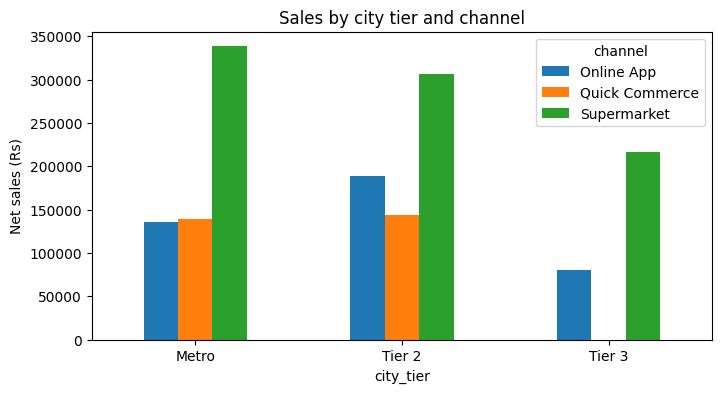

In [5]:
print(clean_df.groupby('channel').discount_pct.mean().round(1).rename('avg discount %'), '\n')
print('Private label share of sales: %.1f%%' % (100*clean_df.loc[clean_df.brand_type=='Private Label','net_amount'].sum()/clean_df.net_amount.sum()))
import matplotlib.pyplot as plt
clean_df.pivot_table(index='city_tier', columns='channel', values='net_amount', aggfunc='sum').plot(kind='bar', figsize=(8,4))
plt.ylabel('Net sales (Rs)'); plt.title('Sales by city tier and channel'); plt.xticks(rotation=0); plt.show()

## 6. Save and download both files

In [6]:
messy.to_csv('grocery_sales_messy.csv', index=False)
clean_df.to_csv('grocery_sales_clean.csv', index=False)
try:
    from google.colab import files
    files.download('grocery_sales_messy.csv'); files.download('grocery_sales_clean.csv')
except ImportError:
    print('Saved to the current folder (not running in Colab).')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>